# Câu 8: Phân tích Return Rate và Rating theo nhóm hàng; xây dựng Heatmap, Scatter/Bubble Chart và nhận xét

### Yêu cầu
* Phân tích tỷ lệ hoàn trả (`Return Rate`) và điểm đánh giá trung bình (`Rating`) theo từng nhóm hàng (`category`).
* Xây dựng biểu đồ **Heatmap** và **Scatter / Bubble Chart** để trực quan hóa mối quan hệ đa chiều.
* Đưa ra nhận xét, đánh giá chất lượng nhóm hàng từ kết quả biểu đồ.

### Dữ liệu cần dùng
* `orders_cleaned.csv`: chứa thông tin đơn hàng (`order_id`, `customer_id`, `category`, `order_status`, `total_amount_usd`, chi phí vận chuyển, thời gian giao hàng, đánh giá/hoàn trả).
* `customers_cleaned.csv`: chứa thông tin địa lý khách hàng (`customer_id`, `country`).
* Hai bảng kết nối với nhau qua khóa `customer_id`.

### Hướng làm
1. Import thư viện và đọc dữ liệu → 2. Ghép bảng (`merge`) lấy thông tin quốc gia và chuẩn hóa biến → 3. Phân tích Return Rate & Rating theo nhóm hàng → 4. Xây dựng Heatmap và Bubble Chart → 5. Nhận xét kết quả.


### 1. Import thư viện và đọc dữ liệu
**Mục tiêu:** Nạp các thư viện xử lý bảng, trực quan hóa và đọc dữ liệu từ 2 file đã làm sạch (`orders_cleaned.csv`, `customers_cleaned.csv`).
* `pandas`, `numpy`: xử lý, làm sạch và tổng hợp dữ liệu.
* `matplotlib`, `seaborn`: vẽ biểu đồ cột kết hợp đường, Heatmap và Bubble Chart.
* `Path`: xử lý đường dẫn file.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.unicode_minus'] = False

# Tự động tìm thư mục chứa file CSV (hỗ trợ cả chạy trong thư mục gốc hoặc thư mục con)
possible_dirs = [Path("../data/cleaned")]
orders_path = next((d / "orders_cleaned.csv" for d in possible_dirs if (d / "orders_cleaned.csv").exists()), None)
customers_path = next((d / "customers_cleaned.csv" for d in possible_dirs if (d / "customers_cleaned.csv").exists()), None)

if orders_path is None or customers_path is None:
    raise FileNotFoundError("Chưa thấy file orders_cleaned.csv hoặc customers_cleaned.csv. Hãy đặt 2 file này vào thư mục data/cleaned/ của dự án!")

orders = pd.read_csv(orders_path)
customers = pd.read_csv(customers_path)

print("Các cột trong orders:", list(orders.columns))
print("Các cột trong customers:", list(customers.columns))
display(orders.head(3))

Các cột trong orders: ['order_id', 'customer_id', 'order_date', 'year', 'month', 'quarter', 'day_of_week', 'product_name', 'category', 'unit_price_usd', 'quantity', 'subtotal_usd', 'discount_pct', 'discount_amount_usd', 'shipping_fee_usd', 'tax_pct', 'tax_amount_usd', 'total_amount_usd', 'payment_method', 'device_used', 'delivery_days', 'delivery_date', 'order_status', 'returned', 'customer_rating', 'session_duration_minutes', 'pages_viewed_before_purchase', 'is_repeat_customer', 'rating_provided']
Các cột trong customers: ['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']


,order_id,customer_id,order_date,year,month,quarter,day_of_week,product_name,category,unit_price_usd,...,device_used,delivery_days,delivery_date,order_status,returned,customer_rating,session_duration_minutes,pages_viewed_before_purchase,is_repeat_customer,rating_provided
0,O000001,C07108,2020-08-27,2020,8,Q3,Thursday,Tire Inflator,Automotive,62.91,...,Desktop,3,2020-08-30,Delivered,0,NaN,14.4,1,1,0
1,O000002,C03487,2024-04-11,2024,4,Q2,Thursday,Stud Earrings Gold,Jewelry & Accessories,18.44,...,Mobile,2,2024-04-13,Delivered,0,NaN,9.0,4,0,0
2,O000003,C03062,2023-06-25,2023,6,Q2,Sunday,Pen Set Premium,Office Supplies,109.79,...,Desktop,3,2023-06-28,Delivered,0,4.0,3.2,17,0,1


### 2. Ghép bảng và chuẩn hóa biến phân tích
**Mục tiêu:** Ghép cột `country` từ bảng `customers` sang `orders` qua `customer_id`, đồng thời tự động chuẩn hóa các cột chỉ số vận chuyển, tỷ lệ hoàn trả (`is_returned`) và điểm đánh giá (`rating`).

In [2]:
# Ghép bảng lấy thông tin quốc gia
df = orders.merge(customers[['customer_id', 'country']], on='customer_id', how='left')

# Hàm hỗ trợ tự tìm tên cột thực tế trong dataset
def find_col(columns, candidates):
    for c in candidates:
        if c in columns:
            return c
    for col in columns:
        for c in candidates:
            if c in col.lower():
                return col
    return None

col_ship_cost = find_col(df.columns, ['shipping_cost', 'shipping_fee', 'freight', 'ship_cost'])
col_ship_days = find_col(df.columns, ['shipping_days', 'delivery_days', 'shipping_time', 'delivery_time'])
col_rating = find_col(df.columns, ['rating', 'review_score', 'customer_rating', 'score'])
col_returned = find_col(df.columns, ['is_returned', 'returned', 'return_flag'])
col_amount = find_col(df.columns, ['total_amount_usd', 'total_amount', 'revenue', 'amount'])

# Nếu chưa có cột số ngày vận chuyển, thử tính từ ngày giao - ngày đặt
if col_ship_days is None:
    col_order_date = find_col(df.columns, ['order_date', 'created_at', 'purchase_date'])
    col_deliv_date = find_col(df.columns, ['delivered_date', 'delivery_date', 'shipped_date'])
    if col_order_date and col_deliv_date:
        df['shipping_days'] = (pd.to_datetime(df[col_deliv_date]) - pd.to_datetime(df[col_order_date])).dt.days
        col_ship_days = 'shipping_days'

# Chuẩn hóa biến hoàn trả về dạng nhị phân (1 = Hoàn trả, 0 = Không hoàn trả)
if col_returned is not None:
    df['is_returned_num'] = pd.to_numeric(df[col_returned], errors='coerce').fillna(
        df[col_returned].astype(str).str.lower().isin(['true', 'yes', '1', 'returned']).astype(int)
    )
elif 'order_status' in df.columns:
    df['is_returned_num'] = df['order_status'].astype(str).str.lower().str.contains('return').astype(int)
else:
    raise KeyError("Không tìm thấy cột trạng thái hoàn trả. Hãy kiểm tra lại tên cột trong orders!")

print(f"Đã ánh xạ cột: Chi phí={col_ship_cost}, Thời gian={col_ship_days}, Rating={col_rating}, Doanh thu={col_amount}")
df[['order_id', 'country', 'category', col_ship_cost, col_ship_days, 'is_returned_num', col_rating]].head()

Đã ánh xạ cột: Chi phí=shipping_fee_usd, Thời gian=delivery_days, Rating=customer_rating, Doanh thu=total_amount_usd


,order_id,country,category,shipping_fee_usd,delivery_days,is_returned_num,customer_rating
0,O000001,United States,Automotive,0.00,3,0,NaN
1,O000002,Germany,Jewelry & Accessories,3.99,2,0,NaN
2,O000003,Italy,Office Supplies,0.00,3,0,4.0
3,O000004,Germany,Electronics,0.00,2,1,NaN
4,O000005,Australia,Jewelry & Accessories,9.99,5,0,2.8


### 4. Phân tích Return Rate và Rating theo nhóm hàng
**Mục tiêu:** Tính tỷ lệ hoàn trả (`Return Rate %`) và điểm đánh giá trung bình (`Rating`) theo từng `category` để phát hiện các nhóm hàng có tỷ lệ hoàn cao hoặc điểm hài lòng thấp.

,category,so_don_hang,tong_doanh_thu,return_rate,avg_rating,avg_ship_days,avg_ship_cost
10,Pet Supplies,751,45074.30,9.32,3.92,4.30,3.61
13,Travel & Luggage,521,91712.79,9.21,4.04,3.96,4.11
7,Home & Kitchen,3068,434212.35,8.80,4.02,4.18,3.90
5,Food & Grocery,1472,59119.13,8.56,4.01,4.16,3.86
12,Toys & Games,1518,114062.97,8.37,4.04,4.18,3.78
2,Books,1962,96013.58,8.26,4.01,4.17,3.82
0,Automotive,768,94446.00,8.07,4.01,4.23,3.64
9,Office Supplies,770,133472.15,8.05,3.95,4.15,3.99
4,Electronics,4526,1148937.00,8.04,3.98,4.18,3.93
6,Health & Wellness,1219,60230.87,7.96,4.02,4.15,3.96


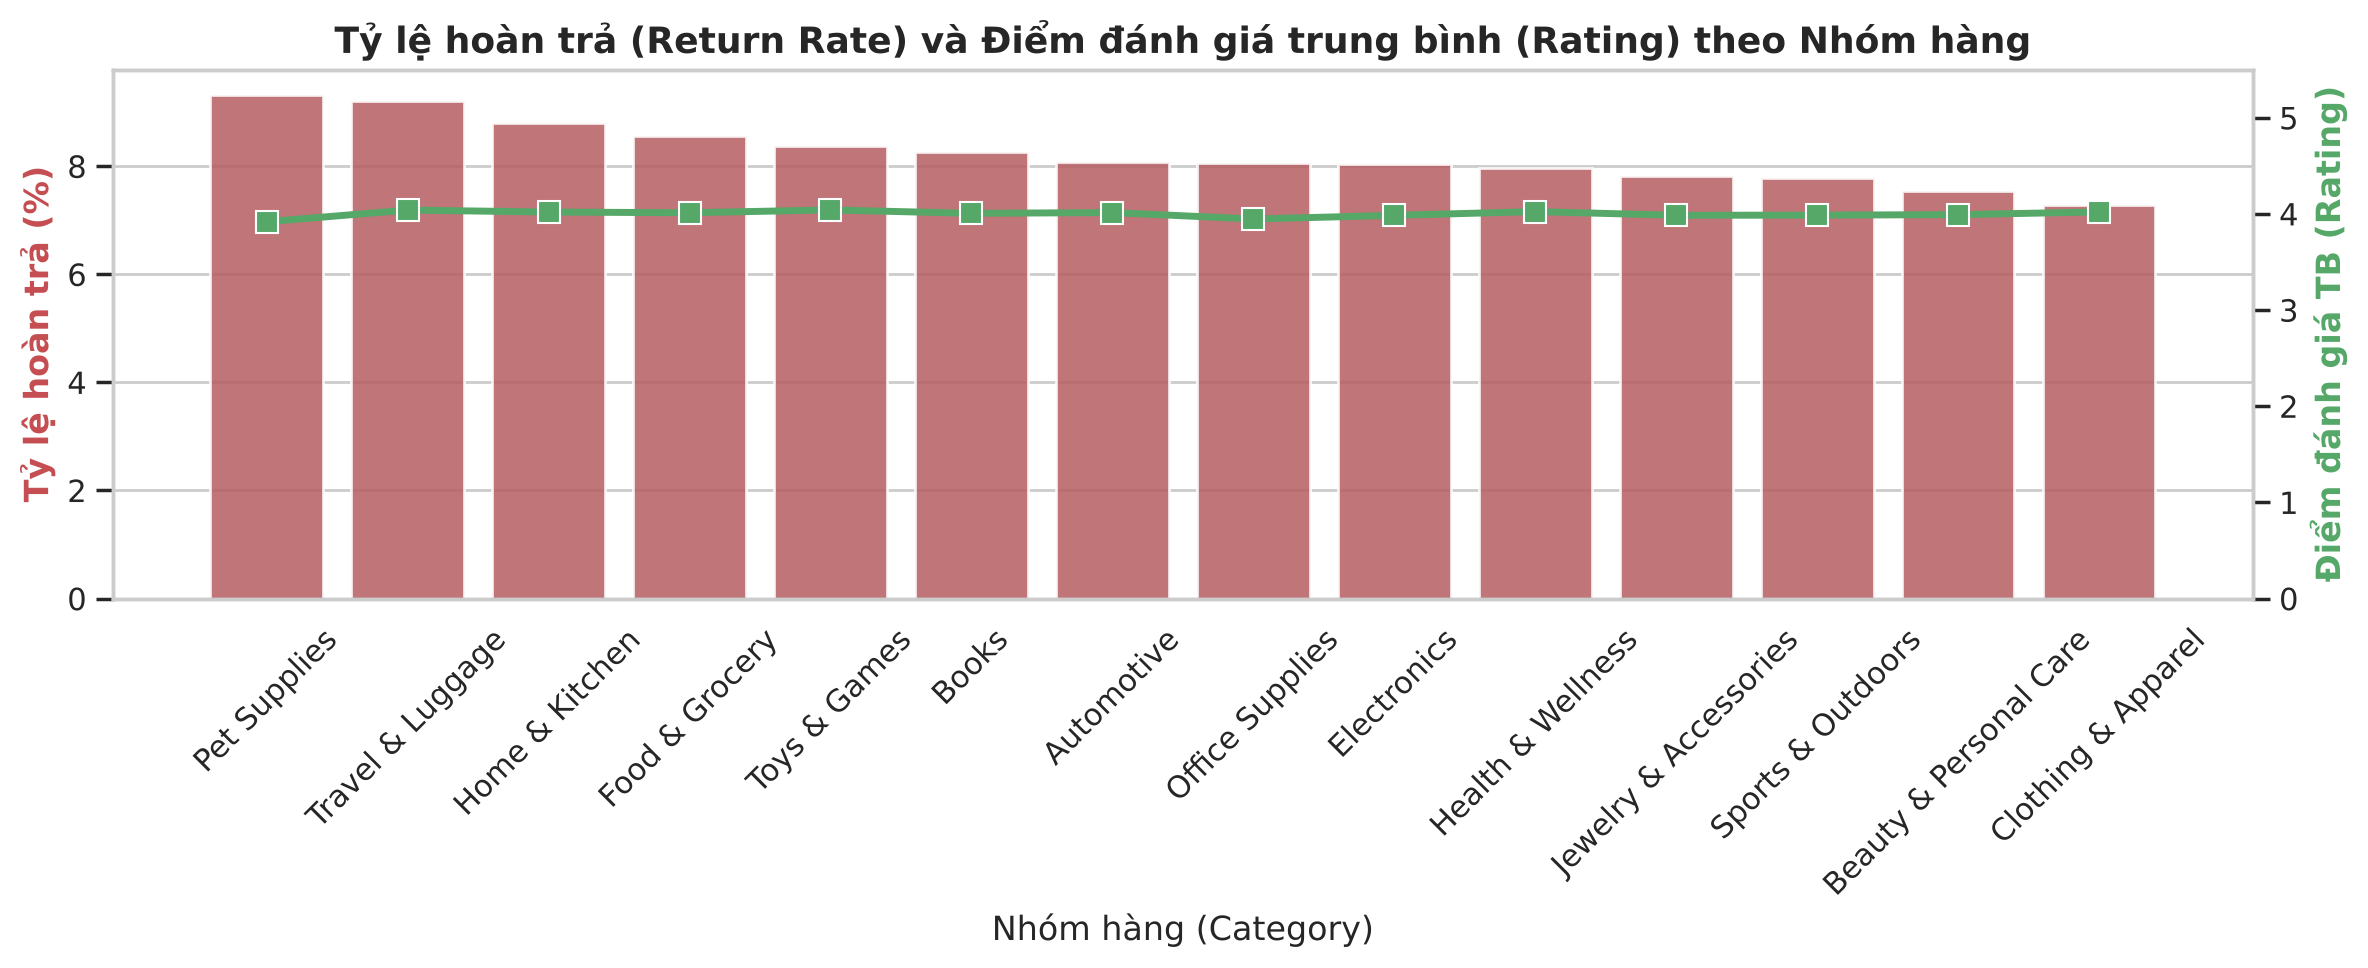

In [3]:
cat_perf = (
    df.groupby('category', as_index=False)
    .agg(
        so_don_hang=('order_id', 'count'),
        tong_doanh_thu=(col_amount, 'sum'),
        return_rate=('is_returned_num', lambda x: x.mean() * 100),
        avg_rating=(col_rating, 'mean'),
        avg_ship_days=(col_ship_days, 'mean'),
        avg_ship_cost=(col_ship_cost, 'mean')
    )
    .sort_values(by='return_rate', ascending=False)
)

display(cat_perf.round(2))

# Vẽ biểu đồ đối chiếu Return Rate (%) và Rating trung bình
fig, ax1 = plt.subplots(figsize=(12, 5))

sns.barplot(data=cat_perf, x='category', y='return_rate', ax=ax1, color='#C44E52', alpha=0.85)
ax1.set_title('Tỷ lệ hoàn trả (Return Rate) và Điểm đánh giá trung bình (Rating) theo Nhóm hàng', fontsize=13, fontweight='bold')
ax1.set_xlabel('Nhóm hàng (Category)')
ax1.set_ylabel('Tỷ lệ hoàn trả (%)', color='#C44E52', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
sns.lineplot(data=cat_perf, x='category', y='avg_rating', ax=ax2, color='#55A868', marker='s', linewidth=2.5, markersize=8)
ax2.set_ylabel('Điểm đánh giá TB (Rating)', color='#55A868', fontweight='bold')
ax2.set_ylim(0, 5.5)
ax2.grid(False)

plt.tight_layout()
plt.savefig('../exports/archive_static_png/cau8_return_rate_rating_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Xây dựng Heatmap và Scatter / Bubble Chart
**Mục tiêu:**
* **Heatmap 1 (Tương quan):** Đánh giá mức độ tương quan tuyến tính giữa chi phí vận chuyển, thời gian giao hàng, tỷ lệ hoàn trả và điểm đánh giá.
* **Heatmap 2 (Quốc gia × Nhóm hàng):** Khoanh vùng các điểm nóng có tỷ lệ hoàn trả (`Return Rate %`) cao bất thường theo từng cặp thị trường – ngành hàng.
* **Bubble Chart:** Trực quan hóa đồng thời 4 chiều dữ liệu: Thời gian vận chuyển TB (trục X), Điểm đánh giá TB (trục Y), Quy mô doanh thu (kích thước bong bóng) và Nhóm hàng (màu sắc).

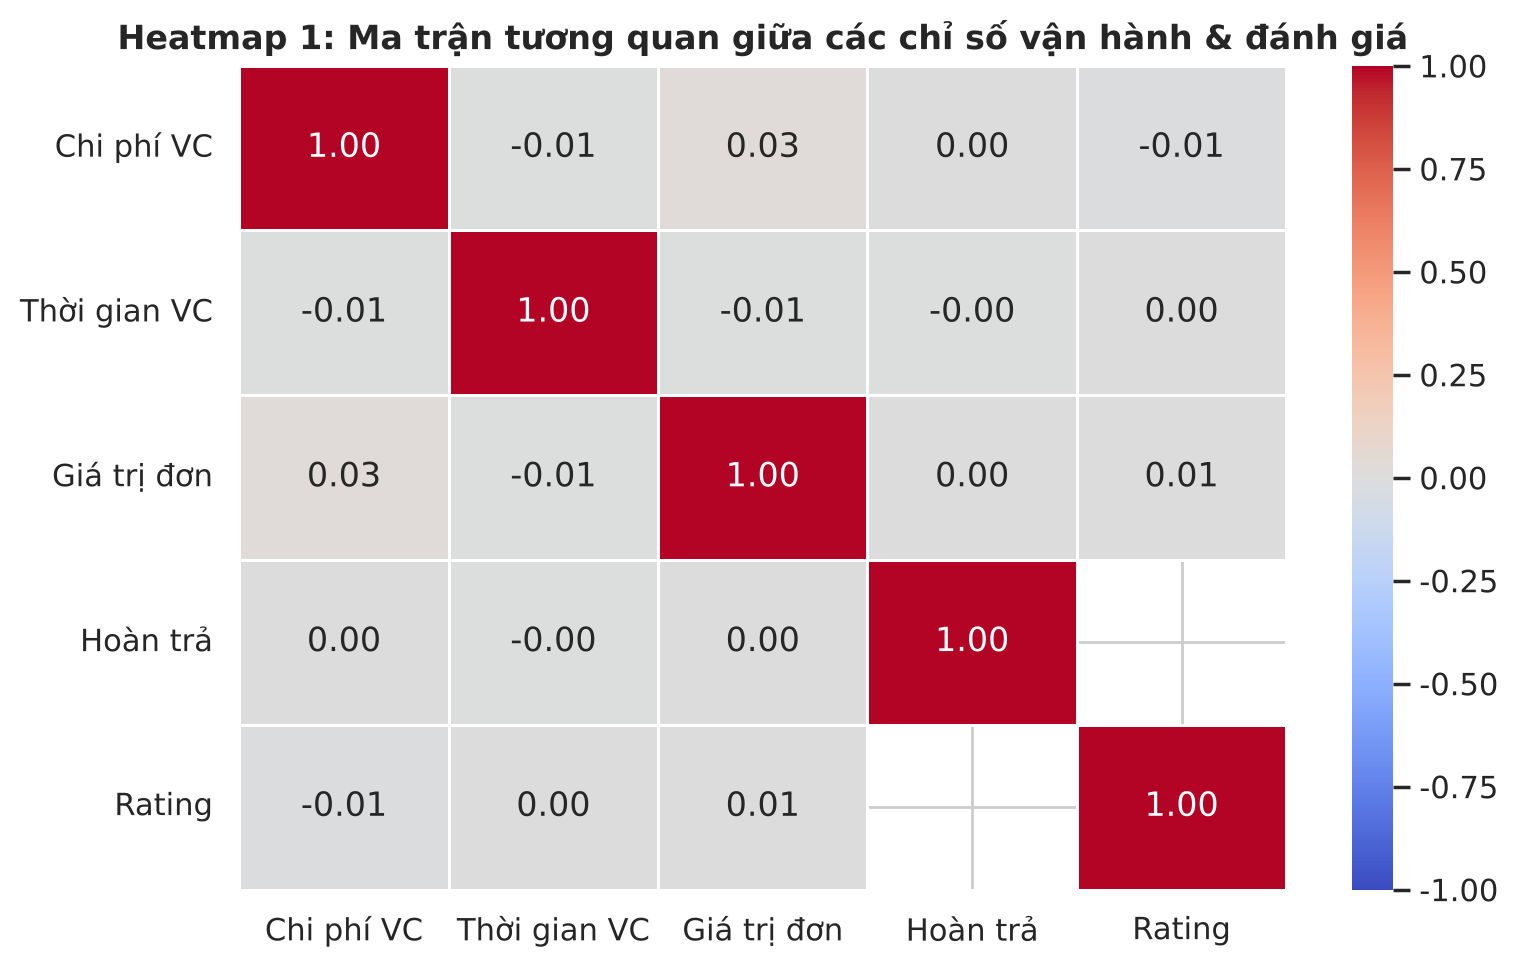

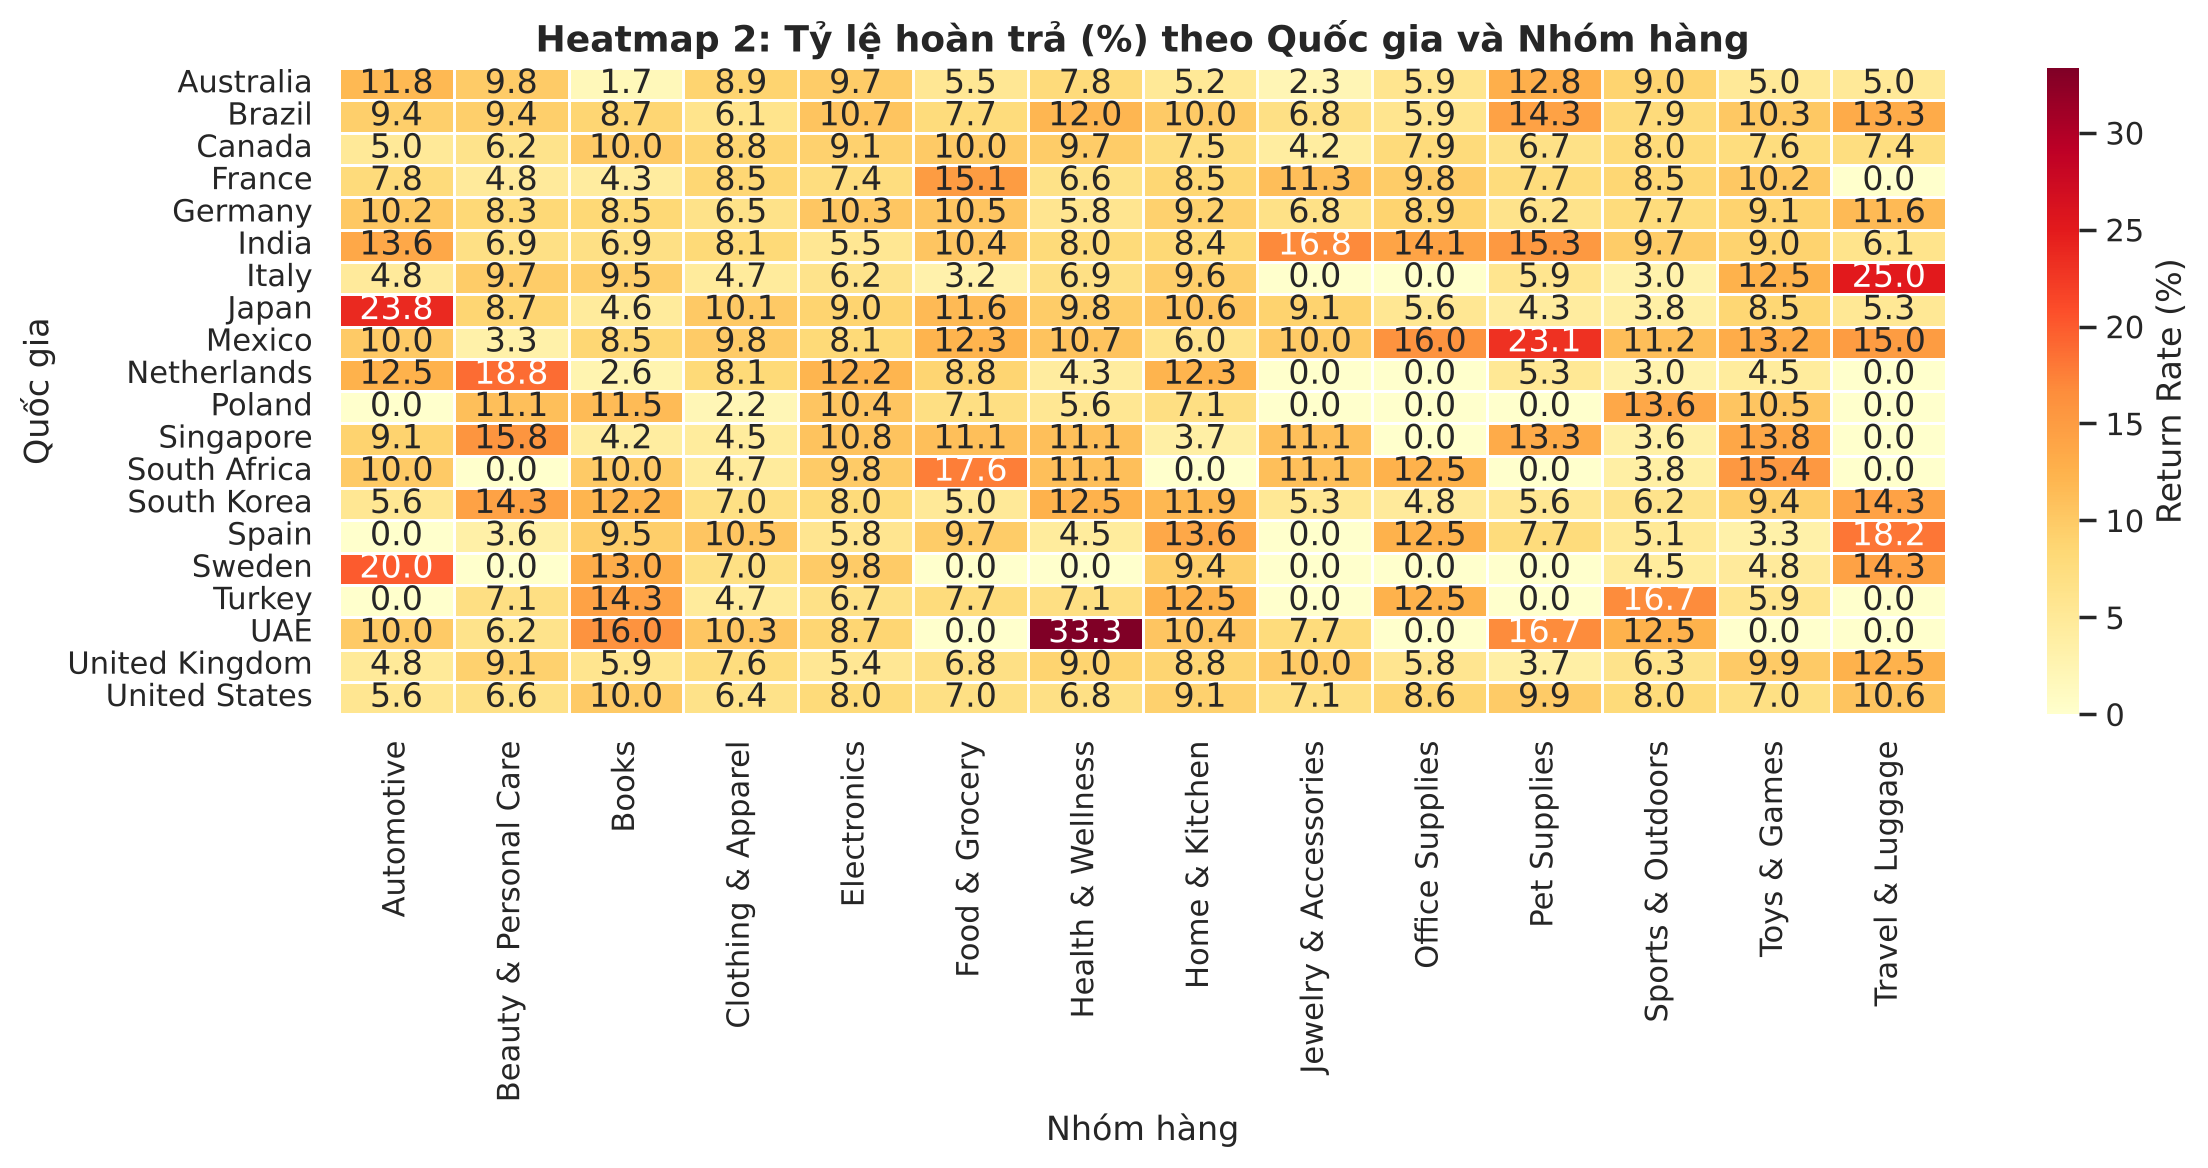

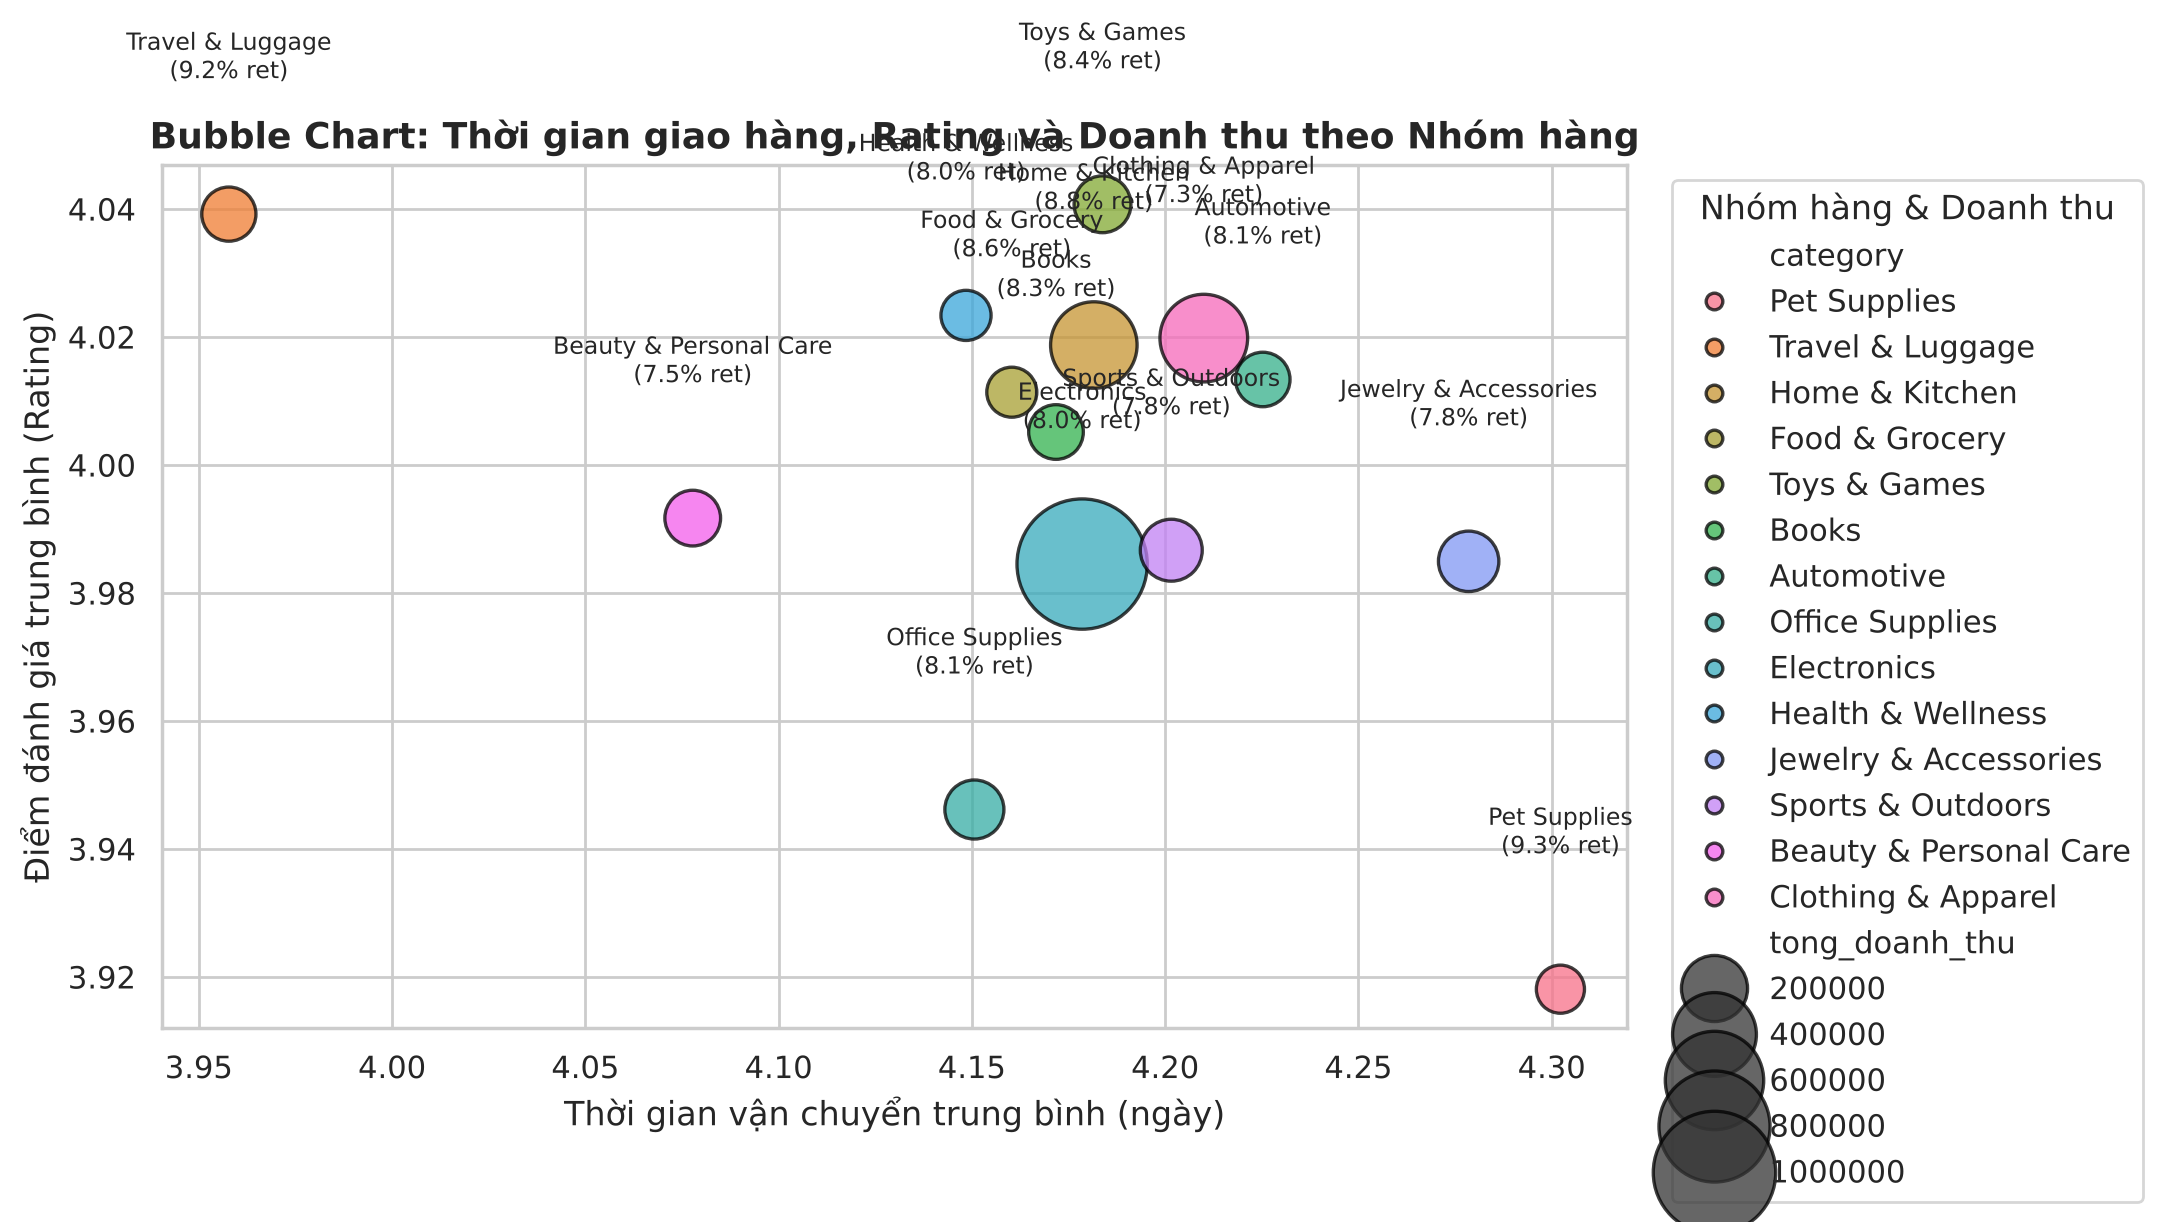

In [4]:
# --- 5A. HEATMAP 1: Ma trận tương quan giữa các biến số ---
corr_cols = [col_ship_cost, col_ship_days, col_amount, 'is_returned_num', col_rating]
corr_df = df[corr_cols].rename(columns={
    col_ship_cost: 'Chi phí VC',
    col_ship_days: 'Thời gian VC',
    col_amount: 'Giá trị đơn',
    'is_returned_num': 'Hoàn trả',
    col_rating: 'Rating'
})

plt.figure(figsize=(8, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap 1: Ma trận tương quan giữa các chỉ số vận hành & đánh giá', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../exports/archive_static_png/cau8_heatmap_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 5B. HEATMAP 2: Tỷ lệ hoàn trả (%) theo Quốc gia và Nhóm hàng ---
pivot_return = df.pivot_table(
    index='country',
    columns='category',
    values='is_returned_num',
    aggfunc=lambda x: x.mean() * 100
)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_return, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5, cbar_kws={'label': 'Return Rate (%)'})
plt.title('Heatmap 2: Tỷ lệ hoàn trả (%) theo Quốc gia và Nhóm hàng', fontsize=13, fontweight='bold')
plt.xlabel('Nhóm hàng')
plt.ylabel('Quốc gia')
plt.tight_layout()
plt.savefig('../exports/archive_static_png/cau8_heatmap_return_country_category.png', dpi=150, bbox_inches='tight')
plt.show()

# --- 5C. BUBBLE CHART: Thời gian giao hàng vs Rating vs Doanh thu ---
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=cat_perf,
    x='avg_ship_days',
    y='avg_rating',
    size='tong_doanh_thu',
    hue='category',
    sizes=(300, 2200),
    alpha=0.75,
    edgecolor='black',
    linewidth=1.2
)

# Gắn nhãn tên nhóm hàng lên từng bong bóng
for _, row in cat_perf.iterrows():
    plt.text(
        row['avg_ship_days'],
        row['avg_rating'] + 0.02,
        f"{row['category']}\n({row['return_rate']:.1f}% ret)",
        fontsize=8.5,
        ha='center',
        va='bottom'
    )

plt.title('Bubble Chart: Thời gian giao hàng, Rating và Doanh thu theo Nhóm hàng', fontsize=13, fontweight='bold')
plt.xlabel('Thời gian vận chuyển trung bình (ngày)')
plt.ylabel('Điểm đánh giá trung bình (Rating)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Nhóm hàng & Doanh thu')
plt.tight_layout()
plt.savefig('../exports/archive_static_png/cau8_bubble_category.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Chạy ô này để lấy chính xác con số thực tế điền vào phần Nhận xét bên dưới
high_ret = cat_perf.iloc[0]
low_ret = cat_perf.iloc[-1]
high_rat = cat_perf.sort_values('avg_rating', ascending=False).iloc[0]
low_rat = cat_perf.sort_values('avg_rating', ascending=True).iloc[0]

print("=== TÓM TẮT SỐ LIỆU ĐỂ VIẾT NHẬN XÉT ===")
print(f"- Nhóm hàng Return Rate cao nhất: {high_ret['category']} ({high_ret['return_rate']:.2f}%) | Thấp nhất: {low_ret['category']} ({low_ret['return_rate']:.2f}%)")
from scipy.stats import spearmanr
rho_rr, p_rr = spearmanr(cat_perf['return_rate'], cat_perf['avg_rating'])
print(f"- Tương quan Spearman giữa Return Rate và Rating ({len(cat_perf)} nhóm hàng): rho = {rho_rr:.2f}, p = {p_rr:.2f}")
print(f"- Nhóm hàng Rating cao nhất: {high_rat['category']} ({high_rat['avg_rating']:.2f}/5) | Thấp nhất: {low_rat['category']} ({low_rat['avg_rating']:.2f}/5)")

=== TÓM TẮT SỐ LIỆU ĐỂ VIẾT NHẬN XÉT ===
- Nhóm hàng Return Rate cao nhất: Pet Supplies (9.32%) | Thấp nhất: Clothing & Apparel (7.28%)
- Tương quan Spearman giữa Return Rate và Rating (14 nhóm hàng): rho = 0.11, p = 0.71
- Nhóm hàng Rating cao nhất: Toys & Games (4.04/5) | Thấp nhất: Pet Supplies (3.92/5)


1. **Về tỷ lệ hoàn trả (Return Rate) và điểm đánh giá (Rating) theo nhóm hàng:**
   * Nhóm hàng **Pet Supplies** có tỷ lệ hoàn trả cao nhất (`9.32%`), trong khi **Clothing & Apparel** có tỷ lệ hoàn thấp nhất (`7.28%`).
   * Về mức độ hài lòng, **Toys & Games** dẫn đầu với điểm trung bình `4.04/5.0`, ngược lại **Pet Supplies** đạt mức thấp nhất (`3.92/5.0`). **Pet Supplies** vừa có tỷ lệ hoàn trả cao nhất vừa có điểm đánh giá thấp nhất, nhưng xét cả 14 nhóm hàng thì tương quan giữa Return Rate và Rating gần như không có (Spearman `ρ ≈ 0.11`, `p ≈ 0.71`) và khoảng chênh giữa các nhóm khá nhỏ (hoàn trả `7.28%`–`9.32%`, rating `3.92`–`4.04`). Vì vậy chưa thể kết luận nhóm hàng hoàn trả nhiều thì được đánh giá thấp.
2. **Từ biểu đồ Heatmap và Bubble Chart:**
   * **Heatmap** giúp xác định rõ mối tương quan giữa các biến vận hành và khoanh vùng chính xác những cặp *(Quốc gia – Nhóm hàng)* có tỷ lệ hoàn trả tăng đột biến, hỗ trợ doanh nghiệp rà soát đúng khâu đóng gói hoặc nhà cung cấp tại thị trường đó.
   * **Bubble Chart** cho thấy bức tranh tổng thể về hiệu quả kinh doanh: các bong bóng kích thước lớn (nhóm hàng đóng góp doanh thu chủ lực) nếu nằm ở khu vực thời gian giao hàng dài hoặc Rating thấp cần được ưu tiên tối ưu chuỗi cung ứng và kiểm soát chất lượng đầu ra.
